In [ ]:
!pip -q install opencv-python-headless pycocotools

import os
import json
import time
import random
import zipfile
import urllib.request
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Training will use the CPU.")

PyTorch: 2.11.0+cpu
Device: cpu
GPU unavailable. Training will use the CPU.


In [ ]:
DATA_DIR = Path("/content/arcade")
ZIP_PATH = Path("/content/arcade.zip")

if not DATA_DIR.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)

if not any(DATA_DIR.iterdir()):
    if not ZIP_PATH.exists():
        print("Downloading ARCADE dataset...")
        url = "https://zenodo.org/records/10390295/files/arcade.zip?download=1"

        try:
            urllib.request.urlretrieve(url, ZIP_PATH)
        except Exception as e:
            raise RuntimeError(
                "Automatic download failed. Download the dataset from "
                "the official Zenodo page and upload the ZIP to Colab."
            ) from e

    print("Extracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(DATA_DIR)

print("Dataset directory:", DATA_DIR)

for path in list(DATA_DIR.rglob("*.json"))[:10]:
    print(path)

Extracting dataset...
Dataset directory: /content/arcade
/content/arcade/arcade/stenosis/val/annotations/val.json
/content/arcade/arcade/stenosis/train/annotations/train.json
/content/arcade/arcade/stenosis/test/annotations/test.json
/content/arcade/arcade/syntax/val/annotations/val.json
/content/arcade/arcade/syntax/train/annotations/train.json
/content/arcade/arcade/syntax/test/annotations/test.json


In [ ]:
all_json_files = list(DATA_DIR.rglob("train.json"))

print("Annotation files found:")
for p in all_json_files:
    print(p)

syntax_json = [
    p for p in all_json_files
    if "syntax" in str(p).lower()
]

if not syntax_json:
    raise FileNotFoundError(
        "Could not find syntax/train/annotations/train.json. "
        "Check the extracted dataset folder structure."
    )

ANNOTATION_FILE = syntax_json[0]
print("\nUsing annotation file:", ANNOTATION_FILE)

with open(ANNOTATION_FILE, "r") as f:
    coco = json.load(f)

print("Images:", len(coco.get("images", [])))
print("Annotations:", len(coco.get("annotations", [])))
print("Categories:", coco.get("categories", []))

Annotation files found:
/content/arcade/arcade/stenosis/train/annotations/train.json
/content/arcade/arcade/syntax/train/annotations/train.json

Using annotation file: /content/arcade/arcade/syntax/train/annotations/train.json
Images: 1000
Annotations: 4976
Categories: [{'id': 1, 'name': '1', 'supercategory': ''}, {'id': 2, 'name': '2', 'supercategory': ''}, {'id': 3, 'name': '3', 'supercategory': ''}, {'id': 4, 'name': '4', 'supercategory': ''}, {'id': 5, 'name': '5', 'supercategory': ''}, {'id': 6, 'name': '6', 'supercategory': ''}, {'id': 7, 'name': '7', 'supercategory': ''}, {'id': 8, 'name': '8', 'supercategory': ''}, {'id': 9, 'name': '9', 'supercategory': ''}, {'id': 10, 'name': '9a', 'supercategory': ''}, {'id': 11, 'name': '10', 'supercategory': ''}, {'id': 12, 'name': '10a', 'supercategory': ''}, {'id': 13, 'name': '11', 'supercategory': ''}, {'id': 14, 'name': '12', 'supercategory': ''}, {'id': 15, 'name': '12a', 'supercategory': ''}, {'id': 16, 'name': '13', 'supercategory'

In [ ]:
IMAGE_ROOT = ANNOTATION_FILE.parent.parent / "images"

if not IMAGE_ROOT.exists():
    raise FileNotFoundError(
        f"Image folder not found: {IMAGE_ROOT}. "
        "Check the dataset structure."
    )

images_by_id = {
    item["id"]: item for item in coco["images"]
}

annotations_by_image = {}

for ann in coco["annotations"]:
    annotations_by_image.setdefault(
        ann["image_id"], []
    ).append(ann)

image_records = []

for image_info in coco["images"]:
    filename = image_info["file_name"]

    image_path = IMAGE_ROOT / filename

    if not image_path.exists():
        matches = list(IMAGE_ROOT.rglob(Path(filename).name))
        if matches:
            image_path = matches[0]
        else:
            continue

    image_records.append({
        "image_id": image_info["id"],
        "image_path": str(image_path),
        "width": image_info.get("width", 512),
        "height": image_info.get("height", 512)
    })

print("Images with accessible files:", len(image_records))

if len(image_records) < 10:
    raise ValueError("Not enough images were found to train the models.")

# Use a sample for a preliminary experiment.
SAMPLE_SIZE = min(50, len(image_records))

sample_records = random.sample(
    image_records,
    SAMPLE_SIZE
)

OUTPUT_DIR = Path("/content/artery_segmentation_data")
IMAGE_OUT = OUTPUT_DIR / "images"
MASK_OUT = OUTPUT_DIR / "masks"

IMAGE_OUT.mkdir(parents=True, exist_ok=True)
MASK_OUT.mkdir(parents=True, exist_ok=True)

processed_records = []

for idx, record in enumerate(sample_records):
    image = cv2.imread(record["image_path"])

    if image is None:
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (512, 512))

    mask = np.zeros((512, 512), dtype=np.uint8)

    annotations = annotations_by_image.get(
        record["image_id"], []
    )

    original_w = record["width"]
    original_h = record["height"]

    for ann in annotations:
        segmentation = ann.get("segmentation", [])

        if isinstance(segmentation, list):
            for polygon in segmentation:
                if len(polygon) < 6:
                    continue

                points = np.array(
                    polygon,
                    dtype=np.float32
                ).reshape(-1, 2)

                points[:, 0] *= 512 / original_w
                points[:, 1] *= 512 / original_h

                points = np.round(points).astype(np.int32)

                cv2.fillPoly(mask, [points], 255)

    image_file = IMAGE_OUT / f"{idx:04d}.png"
    mask_file = MASK_OUT / f"{idx:04d}.png"

    Image.fromarray(image).save(image_file)
    Image.fromarray(mask).save(mask_file)

    processed_records.append({
        "image": str(image_file),
        "mask": str(mask_file),
        "source_image_id": record["image_id"]
    })

print("Image-mask pairs created:", len(processed_records))

if len(processed_records) < 10:
    raise ValueError(
        "Too few image-mask pairs were created. "
        "Check the annotation format and image paths."
    )

Images with accessible files: 1000
Image-mask pairs created: 50


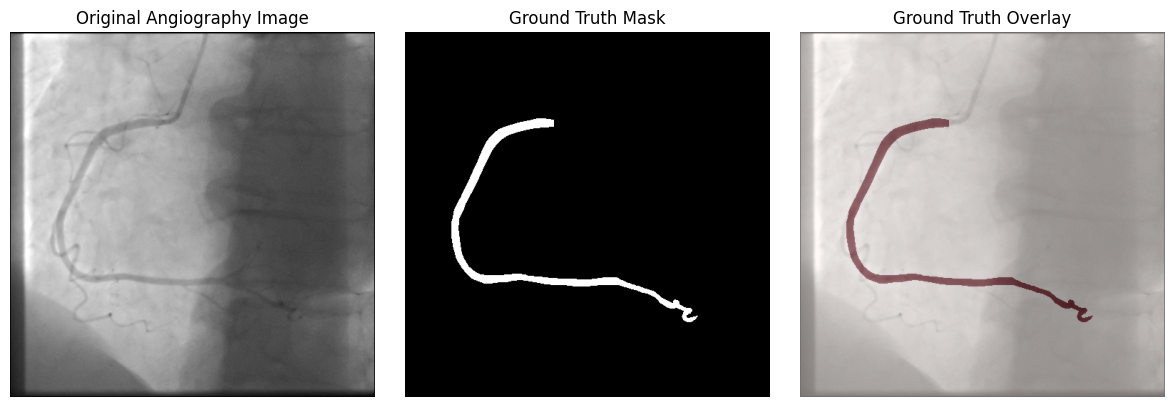

Image shape: (512, 512, 3)
Mask shape: (512, 512)
Mask values: [  0 255]


In [ ]:
sample = processed_records[0]

image = np.array(Image.open(sample["image"]))
mask = np.array(Image.open(sample["mask"]))

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Angiography Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(mask, cmap="Reds", alpha=0.45)
plt.title("Ground Truth Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask values:", np.unique(mask))

In [ ]:
train_records, val_records = train_test_split(
    processed_records,
    test_size=0.20,
    random_state=SEED
)

print("Training images:", len(train_records))
print("Validation images:", len(val_records))

Training images: 40
Validation images: 10


In [ ]:
class ArteryDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]

        image = np.array(
            Image.open(record["image"]).convert("RGB")
        )

        mask = np.array(
            Image.open(record["mask"]).convert("L")
        )

        image = image.astype(np.float32) / 255.0
        mask = (mask > 127).astype(np.float32)

        image = torch.from_numpy(
            image.transpose(2, 0, 1)
        ).float()

        mask = torch.from_numpy(
            mask[None, :, :]
        ).float()

        return image, mask


BATCH_SIZE = 2

train_dataset = ArteryDataset(train_records)
val_dataset = ArteryDataset(val_records)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

images, masks = next(iter(train_loader))

print("Image batch:", images.shape)
print("Mask batch:", masks.shape)

Image batch: torch.Size([2, 3, 512, 512])
Mask batch: torch.Size([2, 1, 512, 512])


In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.dec1 = DoubleConv(64, 32)

        self.output = nn.Conv2d(32, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


unet = UNet().to(DEVICE)

print("U-Net parameters:",
      sum(p.numel() for p in unet.parameters()))

with torch.no_grad():
    sample_output = unet(images.to(DEVICE))

print("Output shape:", sample_output.shape)

U-Net parameters: 7765985
Output shape: torch.Size([2, 1, 512, 512])


In [ ]:
class AttentionGate(nn.Module):
    def __init__(self, gate_channels, skip_channels, inter_channels):
        super().__init__()

        self.gate_conv = nn.Sequential(
            nn.Conv2d(gate_channels, inter_channels, 1),
            nn.BatchNorm2d(inter_channels)
        )

        self.skip_conv = nn.Sequential(
            nn.Conv2d(skip_channels, inter_channels, 1),
            nn.BatchNorm2d(inter_channels)
        )

        self.attention = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.Conv2d(inter_channels, 1, 1),
            nn.Sigmoid()
        )

    def forward(self, gate, skip):
        combined = self.gate_conv(gate) + self.skip_conv(skip)
        attention_map = self.attention(combined)
        return skip * attention_map


class AttentionUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.att4 = AttentionGate(256, 256, 128)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.att3 = AttentionGate(128, 128, 64)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.att2 = AttentionGate(64, 64, 32)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.att1 = AttentionGate(32, 32, 16)
        self.dec1 = DoubleConv(64, 32)

        self.output = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        s4 = self.att4(d4, e4)
        d4 = self.dec4(torch.cat([d4, s4], dim=1))

        d3 = self.up3(d4)
        s3 = self.att3(d3, e3)
        d3 = self.dec3(torch.cat([d3, s3], dim=1))

        d2 = self.up2(d3)
        s2 = self.att2(d2, e2)
        d2 = self.dec2(torch.cat([d2, s2], dim=1))

        d1 = self.up1(d2)
        s1 = self.att1(d1, e1)
        d1 = self.dec1(torch.cat([d1, s1], dim=1))

        return self.output(d1)


attention_unet = AttentionUNet().to(DEVICE)

print("Attention U-Net parameters:",
      sum(p.numel() for p in attention_unet.parameters()))

with torch.no_grad():
    sample_output = attention_unet(images.to(DEVICE))

print("Output shape:", sample_output.shape)

Attention U-Net parameters: 7854709
Output shape: torch.Size([2, 1, 512, 512])


In [ ]:
class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probabilities = torch.sigmoid(logits)

        intersection = (probabilities * targets).sum(
            dim=(1, 2, 3)
        )

        denominator = probabilities.sum(
            dim=(1, 2, 3)
        ) + targets.sum(dim=(1, 2, 3))

        dice = (
            2 * intersection + 1e-7
        ) / (denominator + 1e-7)

        dice_loss = 1 - dice.mean()

        return bce_loss + dice_loss


def train_model(model, model_name, epochs=5):
    criterion = DiceBCELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-4
    )

    history = []

    start_time = time.time()

    for epoch in range(epochs):
        model.train()

        train_loss_total = 0.0

        for batch_images, batch_masks in train_loader:
            batch_images = batch_images.to(DEVICE)
            batch_masks = batch_masks.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(batch_images)
            loss = criterion(outputs, batch_masks)

            loss.backward()
            optimizer.step()

            train_loss_total += loss.item()

        train_loss = train_loss_total / max(
            len(train_loader), 1
        )

        model.eval()
        val_loss_total = 0.0

        with torch.no_grad():
            for batch_images, batch_masks in val_loader:
                batch_images = batch_images.to(DEVICE)
                batch_masks = batch_masks.to(DEVICE)

                outputs = model(batch_images)
                loss = criterion(outputs, batch_masks)

                val_loss_total += loss.item()

        val_loss = val_loss_total / max(
            len(val_loader), 1
        )

        history.append({
            "model": model_name,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        print(
            f"{model_name} | Epoch {epoch + 1}/{epochs} "
            f"| Train Loss: {train_loss:.4f} "
            f"| Val Loss: {val_loss:.4f}"
        )

    elapsed = time.time() - start_time

    print(f"{model_name} training time: {elapsed:.1f} seconds")

    return model, pd.DataFrame(history)


# Use 5 epochs for an initial experiment.
EPOCHS = 5

unet, unet_history = train_model(
    unet, "U-Net", epochs=EPOCHS
)

attention_unet, attention_history = train_model(
    attention_unet, "Attention U-Net", epochs=EPOCHS
)

training_history = pd.concat(
    [unet_history, attention_history],
    ignore_index=True
)

training_history.to_csv(
    "/content/training_history.csv",
    index=False
)

U-Net | Epoch 1/5 | Train Loss: 1.6645 | Val Loss: 1.6547
U-Net | Epoch 2/5 | Train Loss: 1.5511 | Val Loss: 1.5434
U-Net | Epoch 3/5 | Train Loss: 1.4763 | Val Loss: 1.4418
U-Net | Epoch 4/5 | Train Loss: 1.4163 | Val Loss: 1.3882
U-Net | Epoch 5/5 | Train Loss: 1.3792 | Val Loss: 1.3738
U-Net training time: 1843.0 seconds
Attention U-Net | Epoch 1/5 | Train Loss: 1.6130 | Val Loss: 1.6149
Attention U-Net | Epoch 2/5 | Train Loss: 1.4999 | Val Loss: 1.4934
Attention U-Net | Epoch 3/5 | Train Loss: 1.4527 | Val Loss: 1.4312
Attention U-Net | Epoch 4/5 | Train Loss: 1.4217 | Val Loss: 1.4418
Attention U-Net | Epoch 5/5 | Train Loss: 1.4001 | Val Loss: 1.4845
Attention U-Net training time: 1938.5 seconds


In [ ]:
def evaluate_model(model, model_name):
    model.eval()

    tp = 0
    fp = 0
    fn = 0
    tn = 0

    per_image_dice = []

    with torch.no_grad():
        for batch_images, batch_masks in val_loader:
            batch_images = batch_images.to(DEVICE)
            batch_masks = batch_masks.to(DEVICE)

            probabilities = torch.sigmoid(model(batch_images))
            predictions = (probabilities >= 0.5).float()

            tp += ((predictions == 1) & (batch_masks == 1)).sum().item()
            fp += ((predictions == 1) & (batch_masks == 0)).sum().item()
            fn += ((predictions == 0) & (batch_masks == 1)).sum().item()
            tn += ((predictions == 0) & (batch_masks == 0)).sum().item()

            for i in range(len(batch_images)):
                pred = predictions[i]
                target = batch_masks[i]

                intersection = (pred * target).sum().item()

                dice = (
                    2 * intersection + 1e-7
                ) / (
                    pred.sum().item() +
                    target.sum().item() + 1e-7
                )

                per_image_dice.append(dice)

    dice = (2 * tp) / max(2 * tp + fp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)

    result = {
        "Model": model_name,
        "Dice": dice,
        "IoU": iou,
        "Precision": precision,
        "Recall": recall,
        "Accuracy": accuracy,
        "Mean Per-Image Dice": np.mean(per_image_dice),
        "Validation Images": len(per_image_dice),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    }

    return result, per_image_dice


unet_result, unet_per_image_dice = evaluate_model(
    unet, "U-Net"
)

attention_result, attention_per_image_dice = evaluate_model(
    attention_unet, "Attention U-Net"
)

comparison_df = pd.DataFrame([
    unet_result,
    attention_result
])

display(comparison_df.round(4))

,Model,Dice,IoU,Precision,Recall,Accuracy,Mean Per-Image Dice,Validation Images,TP,FP,FN,TN
0,U-Net,0.4688,0.3062,0.3417,0.7463,0.9427,0.4638,10,66303,127728,22537,2404872
1,Attention U-Net,0.4365,0.2792,0.3147,0.7120,0.9377,0.4738,10,63257,137728,25583,2394872


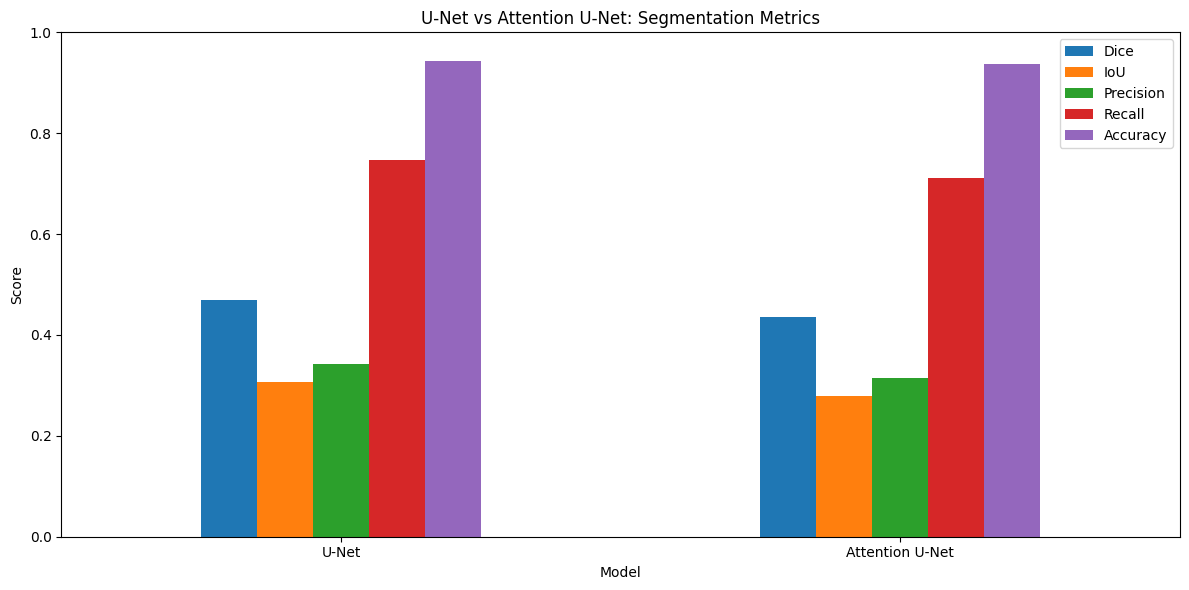

In [ ]:
METRICS = [
    "Dice",
    "IoU",
    "Precision",
    "Recall",
    "Accuracy"
]

ax = comparison_df.set_index("Model")[METRICS].plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("U-Net vs Attention U-Net: Segmentation Metrics")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.tight_layout()

plt.savefig(
    "/content/model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

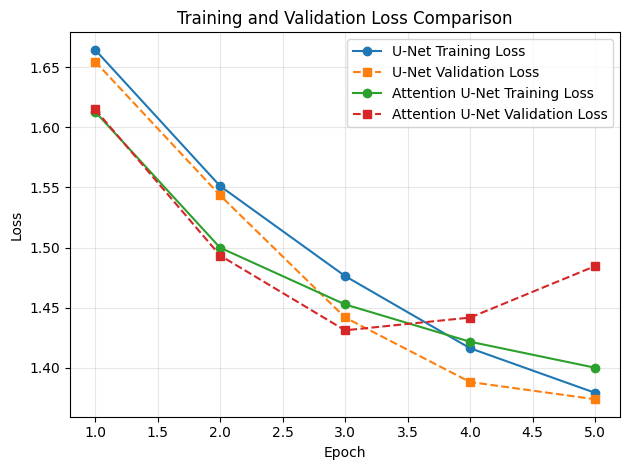

In [ ]:
for model_name in training_history["model"].unique():
    subset = training_history[
        training_history["model"] == model_name
    ]

    plt.plot(
        subset["epoch"],
        subset["train_loss"],
        marker="o",
        label=f"{model_name} Training Loss"
    )

    plt.plot(
        subset["epoch"],
        subset["val_loss"],
        marker="s",
        linestyle="--",
        label=f"{model_name} Validation Loss"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/training_loss_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

,Validation Image,U-Net Dice,Attention U-Net Dice
0,1,0.5283,0.5503
1,2,0.5346,0.5713
2,3,0.2785,0.2643
3,4,0.5684,0.6910
4,5,0.7325,0.7138
5,6,0.4952,0.3753
6,7,0.5266,0.4987
7,8,0.3053,0.2036
8,9,0.5230,0.5887
9,10,0.1450,0.2813


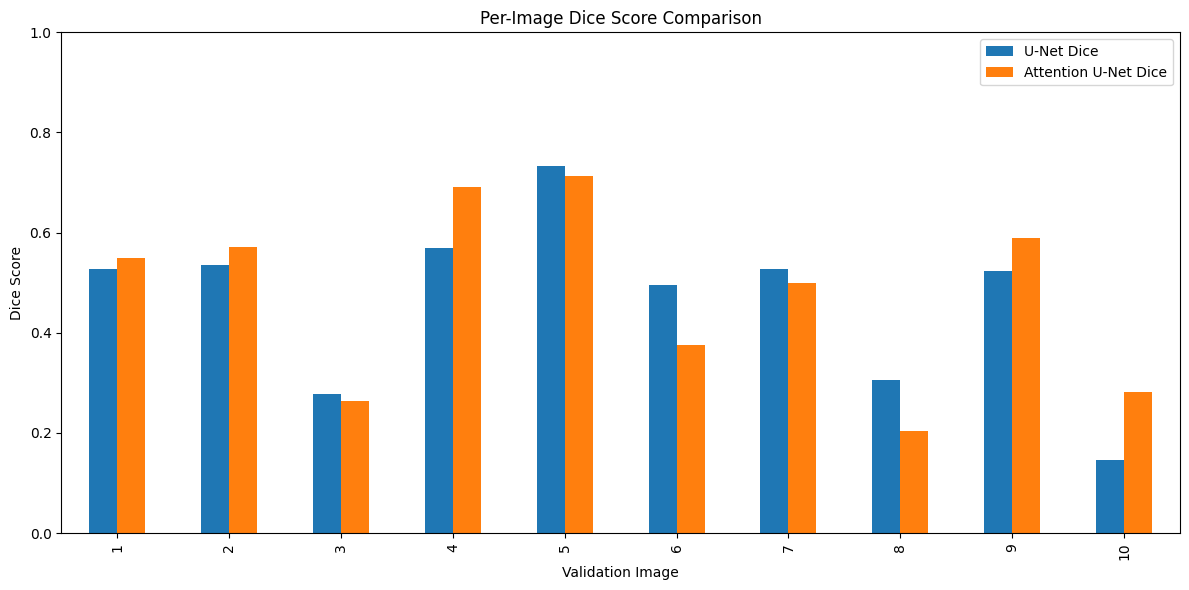

In [ ]:
per_image_df = pd.DataFrame({
    "Validation Image": np.arange(1, len(val_records) + 1),
    "U-Net Dice": unet_per_image_dice,
    "Attention U-Net Dice": attention_per_image_dice
})

display(per_image_df.round(4))

per_image_df.to_csv(
    "/content/per_image_dice_comparison.csv",
    index=False
)

ax = per_image_df.set_index(
    "Validation Image"
).plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Per-Image Dice Score Comparison")
ax.set_ylabel("Dice Score")
ax.set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "/content/per_image_dice_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

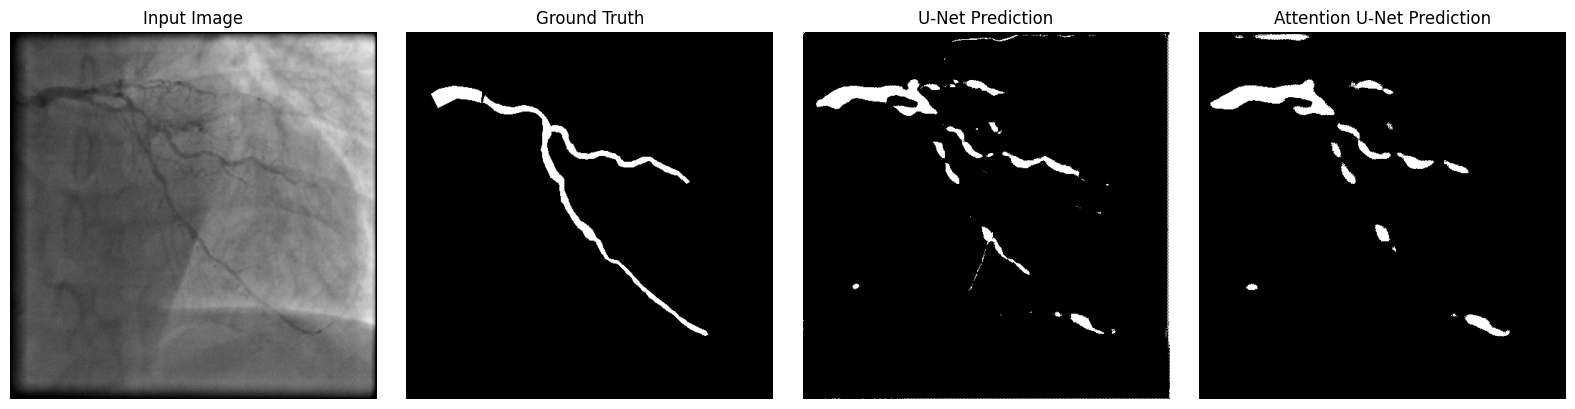

In [ ]:
unet.eval()
attention_unet.eval()

sample_image, sample_mask = val_dataset[0]

with torch.no_grad():
    input_tensor = sample_image.unsqueeze(0).to(DEVICE)

    unet_probability = torch.sigmoid(
        unet(input_tensor)
    )[0, 0].cpu().numpy()

    attention_probability = torch.sigmoid(
        attention_unet(input_tensor)
    )[0, 0].cpu().numpy()

unet_prediction = (unet_probability >= 0.5).astype(np.uint8)
attention_prediction = (
    attention_probability >= 0.5
).astype(np.uint8)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(sample_image.permute(1, 2, 0).numpy())
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(sample_mask[0].numpy(), cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(unet_prediction, cmap="gray")
plt.title("U-Net Prediction")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(attention_prediction, cmap="gray")
plt.title("Attention U-Net Prediction")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "/content/segmentation_prediction_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
REPORT_DIR = Path("/content/segmentation_performance_report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

training_history.to_csv(
    REPORT_DIR / "training_history.csv",
    index=False
)

per_image_df.to_csv(
    REPORT_DIR / "per_image_dice.csv",
    index=False
)

import shutil

for filename in [
    "model_comparison.png",
    "training_loss_comparison.png",
    "per_image_dice_comparison.png",
    "segmentation_prediction_comparison.png"
]:
    source = Path("/content") / filename

    if source.exists():
        shutil.copy2(
            source,
            REPORT_DIR / filename
        )


best_dice_model = comparison_df.loc[
    comparison_df["Dice"].idxmax(), "Model"
]

best_iou_model = comparison_df.loc[
    comparison_df["IoU"].idxmax(), "Model"
]

best_precision_model = comparison_df.loc[
    comparison_df["Precision"].idxmax(), "Model"
]

best_recall_model = comparison_df.loc[
    comparison_df["Recall"].idxmax(), "Model"
]

report_text = f"""
ARTERY SEGMENTATION PERFORMANCE REPORT
======================================

Project:
Artery Segmentation Using Deep Learning

Dataset:
ARCADE coronary angiography dataset

Experiment type:
Preliminary model comparison on a sampled dataset.

Dataset configuration:
- Number of image-mask pairs: {len(processed_records)}
- Training images: {len(train_records)}
- Validation images: {len(val_records)}
- Image size: 512 x 512
- Batch size: {BATCH_SIZE}
- Epochs per model: {EPOCHS}
- Device: {DEVICE}
- Prediction threshold: 0.5

MODEL COMPARISON
----------------

{comparison_df.round(4).to_string(index=False)}

INTERPRETATION
--------------

Model with the highest pooled Dice: {best_dice_model}
Model with the highest pooled IoU: {best_iou_model}
Model with the highest pooled precision: {best_precision_model}
Model with the highest pooled recall: {best_recall_model}

Dice measures overlap between the predicted segmentation and the
ground-truth mask. IoU measures intersection over union.
Precision measures the fraction of predicted foreground pixels
that are correct. Recall measures the fraction of ground-truth
foreground pixels successfully detected.

Accuracy is included for completeness, but it may be misleading
because background pixels can dominate segmentation images.

LIMITATIONS
-----------

1. The experiment uses a small sample of the dataset.
2. Results may vary with random initialization, training settings,
   data selection, and preprocessing.
3. This experiment is not a reproduction of another teammate's
   trained models unless the same architecture, weights, data split,
   and evaluation method are used.
4. The results are not clinically validated and must not be used
   for clinical diagnosis.
5. Further work should evaluate larger training and validation sets,
   tune thresholds using validation data, and evaluate on a separate
   held-out test set.

CONCLUSION
----------

U-Net and Attention U-Net were trained and evaluated using the same
sampled dataset split and evaluation threshold. Their measured
metrics and prediction visualizations are provided in this report.
The preferred model should be selected based on the project's
evaluation criteria and validated on a larger independent dataset.
"""

with open(
    REPORT_DIR / "segmentation_performance_report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(report_text)

print(report_text)
print("\nReport files saved to:", REPORT_DIR)


ARTERY SEGMENTATION PERFORMANCE REPORT

Project:
Artery Segmentation Using Deep Learning

Dataset:
ARCADE coronary angiography dataset

Experiment type:
Preliminary model comparison on a sampled dataset.

Dataset configuration:
- Number of image-mask pairs: 50
- Training images: 40
- Validation images: 10
- Image size: 512 x 512
- Batch size: 2
- Epochs per model: 5
- Device: cpu
- Prediction threshold: 0.5

MODEL COMPARISON
----------------

          Model   Dice    IoU  Precision  Recall  Accuracy  Mean Per-Image Dice  Validation Images    TP     FP    FN      TN
          U-Net 0.4688 0.3062     0.3417  0.7463    0.9427               0.4638                 10 66303 127728 22537 2404872
Attention U-Net 0.4365 0.2792     0.3147  0.7120    0.9377               0.4738                 10 63257 137728 25583 2394872

INTERPRETATION
--------------

Model with the highest pooled Dice: U-Net
Model with the highest pooled IoU: U-Net
Model with the highest pooled precision: U-Net
Model with t

In [ ]:
import shutil
from google.colab import files

ZIP_PATH = "/content/segmentation_performance_report.zip"

shutil.make_archive(
    "/content/segmentation_performance_report",
    "zip",
    REPORT_DIR
)

print("ZIP created:", ZIP_PATH)

files.download(ZIP_PATH)

ZIP created: /content/segmentation_performance_report.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>